In [33]:
# %pip install seaborn
# %pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [16]:
df = pd.read_parquet('../data/green_tripdata_2025-01.parquet')


In [17]:
df.describe()

,VendorID,lpep_pickup_datetime,lpep_dropoff_datetime,RatecodeID,PULocationID,DOLocationID,passenger_count,trip_distance,fare_amount,extra,mta_tax,tip_amount,tolls_amount,ehail_fee,improvement_surcharge,total_amount,payment_type,trip_type,congestion_surcharge,cbd_congestion_fee
count,48326.000000,48326,48326,46490.000000,48326.000000,48326.000000,46490.000000,48326.000000,48326.000000,48326.000000,48326.000000,48326.000000,48326.000000,0.0,48326.000000,48326.000000,46490.000000,46483.000000,46490.00000,46490.000000
mean,1.870215,2025-01-17 04:19:01.965753,2025-01-17 04:38:59.277448,1.184771,94.094545,142.409014,1.278103,21.532410,16.762466,0.932324,0.602776,2.481859,0.177461,NaN,0.988346,22.634242,1.266423,1.038788,0.85306,0.053350
min,1.000000,2024-12-25 23:13:15,2024-12-25 23:13:17,1.000000,3.000000,1.000000,0.000000,0.000000,-113.000000,-5.000000,-0.500000,-0.900000,0.000000,NaN,-1.000000,-114.000000,1.000000,1.000000,-2.75000,0.000000
25%,2.000000,2025-01-09 14:00:31.500000,2025-01-09 14:26:33.500000,1.000000,74.000000,74.000000,1.000000,1.100000,9.300000,0.000000,0.500000,0.000000,0.000000,NaN,1.000000,13.705000,1.000000,1.000000,0.00000,0.000000
50%,2.000000,2025-01-16 19:46:55.500000,2025-01-16 20:01:19.500000,1.000000,75.000000,140.000000,1.000000,1.740000,13.500000,0.000000,0.500000,2.070000,0.000000,NaN,1.000000,18.750000,1.000000,1.000000,0.00000,0.000000
75%,2.000000,2025-01-24 17:47:35.500000,2025-01-24 18:03:52,1.000000,97.000000,230.000000,1.000000,2.940000,19.100000,2.500000,0.500000,3.690000,0.000000,NaN,1.000000,26.465000,2.000000,1.000000,2.75000,0.000000
max,2.000000,2025-02-05 18:46:24,2025-02-05 19:11:47,99.000000,265.000000,265.000000,9.000000,84731.570000,336.200000,7.500000,4.250000,252.050000,48.760000,NaN,1.000000,371.400000,5.000000,2.000000,2.75000,0.750000
std,0.336070,NaN,NaN,1.442502,54.968061,77.251550,0.937178,990.646907,13.308342,1.348587,0.357366,3.213612,1.192984,NaN,0.130402,15.435061,0.471842,0.193092,1.27190,0.192788


In [18]:
df.isnull().sum()

VendorID                     0
lpep_pickup_datetime         0
lpep_dropoff_datetime        0
store_and_fwd_flag        1836
RatecodeID                1836
PULocationID                 0
DOLocationID                 0
passenger_count           1836
trip_distance                0
fare_amount                  0
extra                        0
mta_tax                      0
tip_amount                   0
tolls_amount                 0
ehail_fee                48326
improvement_surcharge        0
total_amount                 0
payment_type              1836
trip_type                 1843
congestion_surcharge      1836
cbd_congestion_fee        1836
dtype: int64

In [19]:
df.duplicated().sum()

np.int64(0)

In [20]:
df.lpep_dropoff_datetime = pd.to_datetime(df.lpep_dropoff_datetime)
df.lpep_pickup_datetime = pd.to_datetime(df.lpep_pickup_datetime)

In [21]:
df['duration'] = df.lpep_dropoff_datetime - df.lpep_pickup_datetime

In [22]:
td = df.duration.iloc[0]
td.total_seconds()/60

14.183333333333334

In [23]:
df.duration = df.duration.apply(lambda td: td.total_seconds()/60)

In [24]:
# df = df[df.trip_type == 2]

In [25]:
df

,VendorID,lpep_pickup_datetime,lpep_dropoff_datetime,store_and_fwd_flag,RatecodeID,PULocationID,DOLocationID,passenger_count,trip_distance,fare_amount,...,tip_amount,tolls_amount,ehail_fee,improvement_surcharge,total_amount,payment_type,trip_type,congestion_surcharge,cbd_congestion_fee,duration
0,2,2025-01-01 00:03:01,2025-01-01 00:17:12,N,1.0,75,235,1.0,5.93,24.70,...,6.80,0.00,NaN,1.0,34.00,1.0,1.0,0.00,0.0,14.183333
1,2,2025-01-01 00:19:59,2025-01-01 00:25:52,N,1.0,166,75,1.0,1.32,8.60,...,0.00,0.00,NaN,1.0,11.10,2.0,1.0,0.00,0.0,5.883333
2,2,2025-01-01 00:05:29,2025-01-01 00:07:21,N,5.0,171,73,1.0,0.41,25.55,...,0.00,0.00,NaN,1.0,26.55,2.0,2.0,0.00,0.0,1.866667
3,2,2025-01-01 00:52:24,2025-01-01 01:07:52,N,1.0,74,223,1.0,4.12,21.20,...,6.13,6.94,NaN,1.0,36.77,1.0,1.0,0.00,0.0,15.466667
4,2,2025-01-01 00:25:05,2025-01-01 01:01:10,N,1.0,66,158,1.0,4.71,33.80,...,7.81,0.00,NaN,1.0,46.86,1.0,1.0,2.75,0.0,36.083333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48321,2,2025-01-31 19:36:00,2025-01-31 20:05:00,NaN,NaN,179,132,NaN,13.99,55.61,...,11.42,0.00,NaN,1.0,68.53,NaN,NaN,NaN,NaN,29.000000
48322,2,2025-01-31 20:33:00,2025-01-31 20:41:00,NaN,NaN,166,75,NaN,1.51,13.58,...,2.26,0.00,NaN,1.0,17.34,NaN,NaN,NaN,NaN,8.000000
48323,2,2025-01-31 21:09:00,2025-01-31 21:30:00,NaN,NaN,41,42,NaN,2.90,30.89,...,0.00,0.00,NaN,1.0,32.39,NaN,NaN,NaN,NaN,21.000000
48324,2,2025-01-31 22:22:00,2025-01-31 22:25:00,NaN,NaN,75,43,NaN,0.34,14.78,...,2.44,0.00,NaN,1.0,18.72,NaN,NaN,NaN,NaN,3.000000


In [31]:
df.duration.describe()

count    48326.000000
mean        19.955195
std         93.924039
min          0.000000
25%          7.200000
50%         11.250000
75%         16.983333
max       1439.650000
Name: duration, dtype: float64

In [27]:
df.duration.value_counts()

duration
0.050000     221
0.066667     180
6.000000     150
0.033333     124
0.083333     123
            ... 
64.000000      1
88.000000      1
59.000000      1
67.016667      1
67.000000      1
Name: count, Length: 3362, dtype: int64

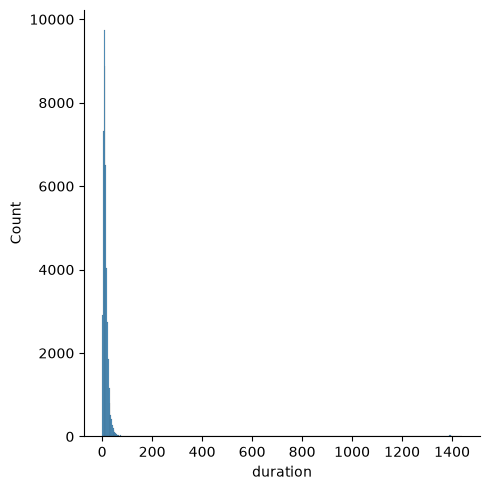

In [28]:
sns.displot(df.duration)

In [30]:
((df.duration >= 1) & (df.duration <= 60)).mean()

np.float64(0.9582212473616687)

<Axes: ylabel='duration'>

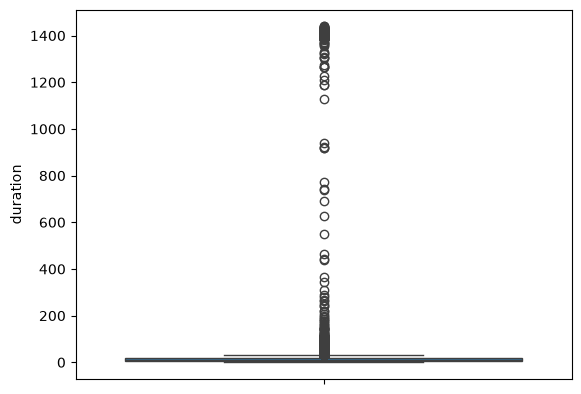

In [32]:
sns.boxplot(df.duration)

In [34]:
categorical = ['PULocationID', 'DOLocationID']
numerical = ['trip_distance']

In [36]:
df[categorical].dtypes

PULocationID    int32
DOLocationID    int32
dtype: object

In [39]:
df[categorical] = df[categorical].astype(str)